## A prototype model for identifying key mutations for FIPV/FECV switch

### 1. Minimum implementation of GWAS-like statistical test

In [36]:
# Arial fontがないためこちらで実行
import pandas as pd
import numpy as np
from Bio import SeqIO
from statsmodels.stats.multitest import multipletests
from scipy.stats import fisher_exact
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.font_manager import FontProperties, findfont

# 1. SVGのフォント設定（テキストとして保持する設定）
mpl.rcParams['svg.fonttype'] = 'none'

# 2. Arialフォントをシステムから検索して設定
try:
    # Arialを探し、パスを取得
    arial_path = findfont(FontProperties(family='Arial'))
    # FontPropertiesを生成
    arial_font = FontProperties(fname=arial_path)
    # matplotlibに適用
    plt.rcParams['font.family'] = arial_font.get_name()
    print(f"Arialフォントを適用しました: {arial_path}")
except Exception as e:
    print(f"Arialが見つかりません。デフォルトフォントを使用します: {e}")
    plt.rcParams['font.family'] = 'sans-serif'

Arialフォントを適用しました: /System/Library/Fonts/Supplemental/Arial.ttf


In [37]:
meta = pd.read_csv("FCoV1_S_all_seq_final_meta_20260306.tsv", sep="\t")
meta

,Accession,biotype,Organism_Name,Isolate,Species,Spike_Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,4407,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,3699,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,3729,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,4398,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,4404,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI
...,...,...,...,...,...,...,...,...,...,...,...,...,...
443,JQ304330.1,FECV,Feline coronavirus,FECV141,taxon:12663,348,NaN,Netherlands,Felis catus,feces,NaN,12-JUL-2012,NCBI
444,FJ917532.1,FIPV,Feline coronavirus,FIPV-UCD11b-1a,taxon:12663,186,NaN,USA,Felis catus (cat),diseased lesional tissue,31-Mar-2008,24-JUL-2016,NCBI
445,PP097359.1,FIPV,Feline coronavirus,FIPV/UGM/BUDF,taxon:12663,360,NaN,Indonesia,Felis catus,ascites,NaN,04-FEB-2024,NCBI
446,JQ304361.1,FECV,Feline coronavirus,FECV378,taxon:12663,543,NaN,Netherlands,Felis catus,feces,NaN,12-JUL-2012,NCBI


In [38]:
# load protien alignment
ids = []
seqs = []

for rec in SeqIO.parse("FCoV1_S_all_seq_cleaned_cds_linsi_curated_fullllength_fix.aa.fasta", "fasta"):
    ids.append(rec.id)
    seqs.append(str(rec.seq))

df_fasta = pd.DataFrame({"ID": ids, "Seq": seqs})
df_fasta

,ID,Seq
0,PQ416775.1,MIVLILALLSTASSEDAPHG-ATLPHFNTSHNNRKFELNFYNFLQTWNIPPNTETILGGYLPYCDGIPNCGWYNFAFQQHD---GLNGKYSYINTQNLNIPNVHGVYFDVRE-R-Y-YDD-GVWDPADKVGLLISIHG-NSHYSLLMVLQDNVEENQPHVAVKICHWK--PGNISTY----HQFTVNLGDGGQCVFNQRFSLDTKLTADDFYGFQWTDTYVDIYLGGTITKVWVDNDWSIVEASISYHWNQANYGYYMQFVNRTTYYAYNSTGGSSHSDLQLVECH---SDYCAGYAKNVFVPIDGKIPESFSFNNWFLLSDKSTLVQGRVLSKQPVFVQCLRPVPAWSNNTAVVHFKDDAFCPNVTADVLRFNLNFSDTDVYTDSSSDDQLYFTFEDNTTASIACYSSANVTDFQPANNSAFHIPFGKTEHSYFCFANFSHSVVSRQFLGILPPTVREFAFGRDGSIFVNGYKYFSLPPIKSVNFSISSVEQYGFWTIAYTNYTDVMVDVNGTGITRLFYCDSPLNRIKCQQLKHELPDGFYSASMLVKKDLPKTFVTMPQFYNWMNVTLHIVLNDTEKGKDIILAKAQELASLADIHFEIAQANGSITNVTSVCVQARQLSLFYKYTSLQGLYTYSNLVELQNYDCPFSPQQFNNYLQFETLCFDVNPAVAGCKWSLVHDNRWRTQFATITVSYKDGSMITTMPKAQ-LGFQDISNLVKGECTDYNIYGFQGTGIIRNTTSRLVAGLYYTSISGDLLAFKNSTTGEIFTVVPCDLTAQAAVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSTSE----SVQTYTMPQFYYITKWNNDTSTNCTSVITYSSFAICNTGEIKYVNVTKVEIVDDSIGVIKPISTGNISIPKNFTVAVQAEYVQIQVKPVVVDCAKYVCNGNRHCLSLLTQYTSACQTIENALNLGARLESLMLNDMITVSDRSLELATVEKFNTTVVGGEKLGGLFFDGLSSLLPPRVGERSAVEDLLFNKVVTSGLGTVDDDYKKCSAGTDVADLVCAQYYNGIMVLPGVVDGNKMAMYTASLIGGMALGSITSAVAVPFAMQVQARLNYVALQTDVLQENQKILANAFNNAIGNITLALGKVSNAITTISDGFNSMASALTKIQSVVNQQGEALSQLTSQLQKNFQAISSSIAEIYNRLEKVEADAQVDRLITGRLAALNAYVSQTLIQYAEVKASRQLAMEKVNECVKSQSDRYGFCGNGTHLFSLVNSAPDGLLFFHTVLLPTGWEEVTAWSGICVNDTYAYVLKDFEYSIFSYSGTYMVTPRNMFQPRKPQMSDFVQITSCEVTFLNTTYTTFQEIVIDYIDINKTIADMLEQYNPNYTTPELDFQLEIFNQTKLNLTAEIDQLEQRADNLTTIAHELQQYIDNLNKTLVDLEWLNRIETYVKWPWYVWLLIGLVVVFCIPLLLFCCLSTGCCGCFGCLGSCCHSLCSRRQFESYEPIEKVHIHX
1,PX315748.1,MIVLILAFVSVVSSNDAPHG-VTLPHFNNSNN----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------SECH---SAYCAGYAKNVFVPIDGKIPESFSFSNWFLLSDKSTLVQGRVLSNQPVFVQCLRPVPTWSNNSAVVYFNNDVFCPNVTADVLRFNLNFSDTDVYTESTNDEQLYFTFEDNTTASLACYSSANVTDFQPASDSVPHVPFGITDHSYFCFANFSHSVVSRQFLGILPPTVREFAFGRDGSIFVNGYKYFSLPPIKSVNFSISSVEQYGFWTIAYTNYTDVMVDVNGTRITRLFYCDSPLNRIKCQQLKYELPDGFYSASMLVKKDLPKTFVTMPQFYNWMNVTLHVVLNDTEKKADIILANAHELASLADIHFEVAQANGSVINVTSLCVQTRQVALFYKYTSLQGLYTYSNLVDLQNYDCPFSPQQFNNHLQFETLCFDVNPAVAGCKWSLVHHNKWRTQFATITVSYKDGSMITTMPQAQ-LGFQDISYLVKDECTDYNVYGFQGTGIIRNTTSRLVAGLYYTSISGDLLAFKNSTTGEIFTVVPCDLTAQVAVINDEIVGAITAINQTDLFEFVNHTQSRSSRRSTPE----TVQTYTMPQFYYITKWNNDTSTNCTSFITYSSFAICNTGEIKYVNVTHVETVDDNIGVIKPISTGNISIPKNFTVAVQAEYIQIQVKPVVVDCAKYVCNGNRHCLALLAQYTSACQTIENALNLGAQLESLMLNDMITVSDRSLALATVETFNSTILGGEKIGGFYSDGLCSLLPPRIGKRSAIEDLLFDKVVTSGLGTVDDDYKKCSAGTDVADLVCAQYYNGIMVLPGVVDQNKMAMYTASLIGGMAMGAITSAVAVPFAMQVQARLNYVALQTDVLQENQKILANAFNNAIGNITLALGKVSNAITTISDGFNSMASALTKIQSVVNQQGEALSQLTSQLQKNFQAISSSIAEIYNRLEKVEADAHVDRLITGRLAALNAYVSQTLTQYSEVKASRQLAMEKVNECVKSQSDRYGFCGNGTHLFSLVNSAPDGLLFFHTVLLPTEWEEVTAWSGICVNDTYAYVLKDFEYSIFSYNNTYMVTPRNMFQPRKPQMSDFVQITSCEVTFLNTTYTTFQEIVIDYIDINKTIADMLEQYNPNYTTPDLDLQLEIFNQTKLNLTAEIDQLEQRADNLTNIAHELQQYIDNLNKTLVDLEWLNRIETYVKWPWYVWLLIGLVIVFCIPLLLFCCLSTGCCGCFGCLGSCCHSLCSRRQFESYEPIEKVHIHX
2,PX315749.1,MIVLILAFVSVVSSHDAPHG-VTLPQFNTSH----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------DNTGGSNYTHLQLNECS---SEYCAGYAKNVFVPIDGKIPEGFSFSNWFLLSDKSTLVQGRVLSSQPVFVQCLRPVPAWSNNTAVVHFKNDAFCPNVTADVLRFNLNFSDTDVFTESTTDDQLYFTFEDNTTASIACYSNANVTDFQPANNSVSHIPLGRTAHAYFCFANFSHSIVSKQFLGVLPPTVRELAFGRDGSIFVNGYKYFSLPPIKSVNFSISSVEQYGFWTIAYTNYTDVMVDVNVTGITRLFYCDSPLNRIKCQQLKHELPDGFYSASMLVKKDLPKTFVTMPQFYDWMNVTLHVVLNDTEKKADIILAKASELASLADIHFEVQQANGSVTNVTSLCVKTRQLSLFYKYTSLQGLYTYSNLVEAQNYDCPFSPQQFNNYLQFETLCFDVNPSVAGCKWSLVHDYKWRTQFATITVSYKDGAMITTMPKAQ-TGFQDISVLLKDECTDYNIYGFHGTGIIRNTTSRLVAGLYYTSTSGDLLAFKNSTTGEIFTVVPCDLTAQAAVINDEIVGVITSVNQTDLFEFVNHTQPRRARKSIFP----TVKTYTMPQFYYITKWNNDTSTNCTSFITYSSFAICNTGEIKYVNVTHVETVDDNIGVIKPISTGNISIPKNFTVAVQAEYIQIQVKPVVVDCAKYVCNGNRHCLSLLSQYTSACQTIENALNLGARLESLMLNDMITVSDRSLD

In [39]:
df_fasta['X_count'] = df_fasta['Seq'].str.count('X')
df_fasta

,ID,Seq,X_count
0,PQ416775.1,MIVLILALLSTASSEDAPHG-ATLPHFNTSHNNRKFELNFYNFLQTWNIPPNTETILGGYLPYCDGIPNCGWYNFAFQQHD---GLNGKYSYINTQNLNIPNVHGVYFDVRE-R-Y-YDD-GVWDPADKVGLLISIHG-NSHYSLLMVLQDNVEENQPHVAVKICHWK--PGNISTY----HQFTVNLGDGGQCVFNQRFSLDTKLTADDFYGFQWTDTYVDIYLGGTITKVWVDNDWSIVEASISYHWNQANYGYYMQFVNRTTYYAYNSTGGSSHSDLQLVECH---SDYCAGYAKNVFVPIDGKIPESFSFNNWFLLSDKSTLVQGRVLSKQPVFVQCLRPVPAWSNNTAVVHFKDDAFCPNVTADVLRFNLNFSDTDVYTDSSSDDQLYFTFEDNTTASIACYSSANVTDFQPANNSAFHIPFGKTEHSYFCFANFSHSVVSRQFLGILPPTVREFAFGRDGSIFVNGYKYFSLPPIKSVNFSISSVEQYGFWTIAYTNYTDVMVDVNGTGITRLFYCDSPLNRIKCQQLKHELPDGFYSASMLVKKDLPKTFVTMPQFYNWMNVTLHIVLNDTEKGKDIILAKAQELASLADIHFEIAQANGSITNVTSVCVQARQLSLFYKYTSLQGLYTYSNLVELQNYDCPFSPQQFNNYLQFETLCFDVNPAVAGCKWSLVHDNRWRTQFATITVSYKDGSMITTMPKAQ-LGFQDISNLVKGECTDYNIYGFQGTGIIRNTTSRLVAGLYYTSISGDLLAFKNSTTGEIFTVVPCDLTAQAAVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSTSE----SVQTYTMPQFYYITKWNNDTSTNCTSVITYSSFAICNTGEIKYVNVTKVEIVDDSIGVIKPISTGNISIPKNFTVAVQAEYVQIQVKPVVVDCAKYVCNGNRHCLSLLTQYTSACQTIENALNLGARLESLMLNDMITVSDRSLELATVEKFNTTVVGGEKLGGLFFDGLSSLLPPRVGERSAVEDLLFNKVVTSGLGTVDDDYKKCSAGTDVADLVCAQYYNGIMVLPGVVDGNKMAMYTASLIGGMALGSITSAVAVPFAMQVQARLNYVALQTDVLQENQKILANAFNNAIGNITLALGKVSNAITTISDGFNSMASALTKIQSVVNQQGEALSQLTSQLQKNFQAISSSIAEIYNRLEKVEADAQVDRLITGRLAALNAYVSQTLIQYAEVKASRQLAMEKVNECVKSQSDRYGFCGNGTHLFSLVNSAPDGLLFFHTVLLPTGWEEVTAWSGICVNDTYAYVLKDFEYSIFSYSGTYMVTPRNMFQPRKPQMSDFVQITSCEVTFLNTTYTTFQEIVIDYIDINKTIADMLEQYNPNYTTPELDFQLEIFNQTKLNLTAEIDQLEQRADNLTTIAHELQQYIDNLNKTLVDLEWLNRIETYVKWPWYVWLLIGLVVVFCIPLLLFCCLSTGCCGCFGCLGSCCHSLCSRRQFESYEPIEKVHIHX,1
1,PX315748.1,MIVLILAFVSVVSSNDAPHG-VTLPHFNNSNN----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------SECH---SAYCAGYAKNVFVPIDGKIPESFSFSNWFLLSDKSTLVQGRVLSNQPVFVQCLRPVPTWSNNSAVVYFNNDVFCPNVTADVLRFNLNFSDTDVYTESTNDEQLYFTFEDNTTASLACYSSANVTDFQPASDSVPHVPFGITDHSYFCFANFSHSVVSRQFLGILPPTVREFAFGRDGSIFVNGYKYFSLPPIKSVNFSISSVEQYGFWTIAYTNYTDVMVDVNGTRITRLFYCDSPLNRIKCQQLKYELPDGFYSASMLVKKDLPKTFVTMPQFYNWMNVTLHVVLNDTEKKADIILANAHELASLADIHFEVAQANGSVINVTSLCVQTRQVALFYKYTSLQGLYTYSNLVDLQNYDCPFSPQQFNNHLQFETLCFDVNPAVAGCKWSLVHHNKWRTQFATITVSYKDGSMITTMPQAQ-LGFQDISYLVKDECTDYNVYGFQGTGIIRNTTSRLVAGLYYTSISGDLLAFKNSTTGEIFTVVPCDLTAQVAVINDEIVGAITAINQTDLFEFVNHTQSRSSRRSTPE----TVQTYTMPQFYYITKWNNDTSTNCTSFITYSSFAICNTGEIKYVNVTHVETVDDNIGVIKPISTGNISIPKNFTVAVQAEYIQIQVKPVVVDCAKYVCNGNRHCLALLAQYTSACQTIENALNLGAQLESLMLNDMITVSDRSLALATVETFNSTILGGEKIGGFYSDGLCSLLPPRIGKRSAIEDLLFDKVVTSGLGTVDDDYKKCSAGTDVADLVCAQYYNGIMVLPGVVDQNKMAMYTASLIGGMAMGAITSAVAVPFAMQVQARLNYVALQTDVLQENQKILANAFNNAIGNITLALGKVSNAITTISDGFNSMASALTKIQSVVNQQGEALSQLTSQLQKNFQAISSSIAEIYNRLEKVEADAHVDRLITGRLAALNAYVSQTLTQYSEVKASRQLAMEKVNECVKSQSDRYGFCGNGTHLFSLVNSAPDGLLFFHTVLLPTEWEEVTAWSGICVNDTYAYVLKDFEYSIFSYNNTYMVTPRNMFQPRKPQMSDFVQITSCEVTFLNTTYTTFQEIVIDYIDINKTIADMLEQYNPNYTTPDLDLQLEIFNQTKLNLTAEIDQLEQRADNLTNIAHELQQYIDNLNKTLVDLEWLNRIETYVKWPWYVWLLIGLVIVFCIPLLLFCCLSTGCCGCFGCLGSCCHSLCSRRQFESYEPIEKVHIHX,1
2,PX315749.1,MIVLILAFVSVVSSHDAPHG-VTLPQFNTSH----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------DNTGGSNYTHLQLNECS---SEYCAGYAKNVFVPIDGKIPEGFSFSNWFLLSDKSTLVQGRVLSSQPVFVQCLRPVPAWSNNTAVVHFKNDAFCPNVTADVLRFNLNFSDTDVFTESTTDDQLYFTFEDNTTASIACYSNANVTDFQPANNSVSHIPLGRTAHAYFCFANFSHSIVSKQFLGVLPPTVRELAFGRDGSIFVNGYKYFSLPPIKSVNFSISSVEQYGFWTIAYTNYTDVMVDVNVTGITRLFYCDSPLNRIKCQQLKHELPDGFYSASMLVKKDLPKTFVTMPQFYDWMNVTLHVVLNDTEKKADIILAKASELASLADIHFEVQQANGSVTNVTSLCVKTRQLSLFYKYTSLQGLYTYSNLVEAQNYDCPFSPQQFNNYLQFETLCFDVNPSVAGCKWSLVHDYKWRTQFATITVSYKDGAMITTMPKAQ-TGFQDISVLLKDECTDYNIYGFHGTGIIRNTTSRLVAGLYYTSTSGDLLAFKNSTTGEIFTVVPCDLTAQAAVINDEIVGVITSVNQTDLFEFVNHTQPRRARKSIFP----TVKTYTMPQFYYITKWNNDTSTNCTSFITYSSFAICNTGEIKYVNVTHVETVDDNIGVIKPISTGNISIPKNFTVAVQAEYIQIQVKPVVVDCAKYVCNGNRHCLSLLSQYTSACQTIENALNLGARLESLML

In [40]:
df_merged = pd.merge(meta, df_fasta, how="inner", left_on="Accession", right_on="ID")
df_merged

,Accession,biotype,Organism_Name,Isolate,Species,Spike_Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,ID,Seq,X_count
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,4407,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,PQ416775.1,MIVLILALLSTASSEDAPHG-ATLPHFNTSHNNRKFELNFYNFLQTWNIPPNTETILGGYLPYCDGIPNCGWYNFAFQQHD---GLNGKYSYINTQNLNIPNVHGVYFDVRE-R-Y-YDD-GVWDPADKVGLLISIHG-NSHYSLLMVLQDNVEENQPHVAVKICHWK--PGNISTY----HQFTVNLGDGGQCVFNQRFSLDTKLTADDFYGFQWTDTYVDIYLGGTITKVWVDNDWSIVEASISYHWNQANYGYYMQFVNRTTYYAYNSTGGSSHSDLQLVECH---SDYCAGYAKNVFVPIDGKIPESFSFNNWFLLSDKSTLVQGRVLSKQPVFVQCLRPVPAWSNNTAVVHFKDDAFCPNVTADVLRFNLNFSDTDVYTDSSSDDQLYFTFEDNTTASIACYSSANVTDFQPANNSAFHIPFGKTEHSYFCFANFSHSVVSRQFLGILPPTVREFAFGRDGSIFVNGYKYFSLPPIKSVNFSISSVEQYGFWTIAYTNYTDVMVDVNGTGITRLFYCDSPLNRIKCQQLKHELPDGFYSASMLVKKDLPKTFVTMPQFYNWMNVTLHIVLNDTEKGKDIILAKAQELASLADIHFEIAQANGSITNVTSVCVQARQLSLFYKYTSLQGLYTYSNLVELQNYDCPFSPQQFNNYLQFETLCFDVNPAVAGCKWSLVHDNRWRTQFATITVSYKDGSMITTMPKAQ-LGFQDISNLVKGECTDYNIYGFQGTGIIRNTTSRLVAGLYYTSISGDLLAFKNSTTGEIFTVVPCDLTAQAAVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSTSE----SVQTYTMPQFYYITKWNNDTSTNCTSVITYSSFAICNTGEIKYVNVTKVEIVDDSIGVIKPISTGNISIPKNFTVAVQAEYVQIQVKPVVVDCAKYVCNGNRHCLSLLTQYTSACQTIENALNLGARLESLMLNDMITVSDRSLELATVEKFNTTVVGGEKLGGLFFDGLSSLLPPRVGERSAVEDLLFNKVVTSGLGTVDDDYKKCSAGTDVADLVCAQYYNGIMVLPGVVDGNKMAMYTASLIGGMALGSITSAVAVPFAMQVQARLNYVALQTDVLQENQKILANAFNNAIGNITLALGKVSNAITTISDGFNSMASALTKIQSVVNQQGEALSQLTSQLQKNFQAISSSIAEIYNRLEKVEADAQVDRLITGRLAALNAYVSQTLIQYAEVKASRQLAMEKVNECVKSQSDRYGFCGNGTHLFSLVNSAPDGLLFFHTVLLPTGWEEVTAWSGICVNDTYAYVLKDFEYSIFSYSGTYMVTPRNMFQPRKPQMSDFVQITSCEVTFLNTTYTTFQEIVIDYIDINKTIADMLEQYNPNYTTPELDFQLEIFNQTKLNLTAEIDQLEQRADNLTTIAHELQQYIDNLNKTLVDLEWLNRIETYVKWPWYVWLLIGLVVVFCIPLLLFCCLSTGCCGCFGCLGSCCHSLCSRRQFESYEPIEKVHIHX,1
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,3699,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,PX315748.1,MIVLILAFVSVVSSNDAPHG-VTLPHFNNSNN----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------SECH---SAYCAGYAKNVFVPIDGKIPESFSFSNWFLLSDKSTLVQGRVLSNQPVFVQCLRPVPTWSNNSAVVYFNNDVFCPNVTADVLRFNLNFSDTDVYTESTNDEQLYFTFEDNTTASLACYSSANVTDFQPASDSVPHVPFGITDHSYFCFANFSHSVVSRQFLGILPPTVREFAFGRDGSIFVNGYKYFSLPPIKSVNFSISSVEQYGFWTIAYTNYTDVMVDVNGTRITRLFYCDSPLNRIKCQQLKYELPDGFYSASMLVKKDLPKTFVTMPQFYNWMNVTLHVVLNDTEKKADIILANAHELASLADIHFEVAQANGSVINVTSLCVQTRQVALFYKYTSLQGLYTYSNLVDLQNYDCPFSPQQFNNHLQFETLCFDVNPAVAGCKWSLVHHNKWRTQFATITVSYKDGSMITTMPQAQ-LGFQDISYLVKDECTDYNVYGFQGTGIIRNTTSRLVAGLYYTSISGDLLAFKNSTTGEIFTVVPCDLTAQVAVINDEIVGAITAINQTDLFEFVNHTQSRSSRRSTPE----TVQTYTMPQFYYITKWNNDTSTNCTSFITYSSFAICNTGEIKYVNVTHVETVDDNIGVIKPISTGNISIPKNFTVAVQAEYIQIQVKPVVVDCAKYVCNGNRHCLALLAQYTSACQTIENALNLGAQLESLMLNDMITVSDRSLALATVETFNSTILGGEKIGGFYSDGLCSLLPPRIGKRSAIEDLLFDKVVTSGLGTVDDDYKKCSAGTDVADLVCAQYYNGIMVLPGVVDQNKMAMYTASLIGGMAMGAITSAVAVPFAMQVQARLNYVALQTDVLQENQKILANAFNNAIGNITLALGKVSNAITTISDGFNSMASALTKIQSVVNQQGEALSQLTSQLQKNFQAISSSIAEIYNRLEKVEADAHVDRLITGRLAALNAYVSQTLTQYSEVKASRQLAMEKVNECVKSQSDRYGFCGNGTHLFSLVNSAPDGLLFFHTVLLPTEWEEVTAWSGICVNDTYAYVLKDFEYSIFSYNNTYMVTPRNMFQPRKPQMSDFVQITSCEVTFLNTTYTTFQEIVIDYIDINKTIADMLEQYNPNYTTPDLDLQLEIFNQTKLNLTAEIDQLEQRADNLTNIAHELQQYIDNLNKTLVDLEWLNRIETYVKWPWYVWLLIGLVIVFCIPLLLFCCLSTGCCGCFGCLGSCCHSLCSRRQFESYEPIEKVHIHX,1
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,3729,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI,PX315749.1,MIVLILAFVSVVSSHDAPHG-VTLPQFNTSH----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------DNTGGSNYTHLQLNECS---SEYCAGYAKNVFVPIDGKIPEGFSFSNWFLLSDKSTLVQGRVLSSQPVFVQCLRPVPAWSNNTAVVHFKNDAFCPNVTADVLRFNLNFSD

In [41]:
df_merged_filtered = df_merged[df_merged['X_count'] < 100]
# replace 'FECV' in 'FECV_or_FIPV' with '0' and 'FIPV' with '1' and 'unknown' with '' for better encoding
df_merged_filtered['FECV_or_FIPV_encodes'] = df_merged_filtered['biotype'].replace({'FECV': '0', 'FIPV': '1', 'unknown': ''})
df_merged_filtered

,Accession,biotype,Organism_Name,Isolate,Species,Spike_Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,ID,Seq,X_count,FECV_or_FIPV_encodes
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,4407,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,PQ416775.1,MIVLILALLSTASSEDAPHG-ATLPHFNTSHNNRKFELNFYNFLQTWNIPPNTETILGGYLPYCDGIPNCGWYNFAFQQHD---GLNGKYSYINTQNLNIPNVHGVYFDVRE-R-Y-YDD-GVWDPADKVGLLISIHG-NSHYSLLMVLQDNVEENQPHVAVKICHWK--PGNISTY----HQFTVNLGDGGQCVFNQRFSLDTKLTADDFYGFQWTDTYVDIYLGGTITKVWVDNDWSIVEASISYHWNQANYGYYMQFVNRTTYYAYNSTGGSSHSDLQLVECH---SDYCAGYAKNVFVPIDGKIPESFSFNNWFLLSDKSTLVQGRVLSKQPVFVQCLRPVPAWSNNTAVVHFKDDAFCPNVTADVLRFNLNFSDTDVYTDSSSDDQLYFTFEDNTTASIACYSSANVTDFQPANNSAFHIPFGKTEHSYFCFANFSHSVVSRQFLGILPPTVREFAFGRDGSIFVNGYKYFSLPPIKSVNFSISSVEQYGFWTIAYTNYTDVMVDVNGTGITRLFYCDSPLNRIKCQQLKHELPDGFYSASMLVKKDLPKTFVTMPQFYNWMNVTLHIVLNDTEKGKDIILAKAQELASLADIHFEIAQANGSITNVTSVCVQARQLSLFYKYTSLQGLYTYSNLVELQNYDCPFSPQQFNNYLQFETLCFDVNPAVAGCKWSLVHDNRWRTQFATITVSYKDGSMITTMPKAQ-LGFQDISNLVKGECTDYNIYGFQGTGIIRNTTSRLVAGLYYTSISGDLLAFKNSTTGEIFTVVPCDLTAQAAVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSTSE----SVQTYTMPQFYYITKWNNDTSTNCTSVITYSSFAICNTGEIKYVNVTKVEIVDDSIGVIKPISTGNISIPKNFTVAVQAEYVQIQVKPVVVDCAKYVCNGNRHCLSLLTQYTSACQTIENALNLGARLESLMLNDMITVSDRSLELATVEKFNTTVVGGEKLGGLFFDGLSSLLPPRVGERSAVEDLLFNKVVTSGLGTVDDDYKKCSAGTDVADLVCAQYYNGIMVLPGVVDGNKMAMYTASLIGGMALGSITSAVAVPFAMQVQARLNYVALQTDVLQENQKILANAFNNAIGNITLALGKVSNAITTISDGFNSMASALTKIQSVVNQQGEALSQLTSQLQKNFQAISSSIAEIYNRLEKVEADAQVDRLITGRLAALNAYVSQTLIQYAEVKASRQLAMEKVNECVKSQSDRYGFCGNGTHLFSLVNSAPDGLLFFHTVLLPTGWEEVTAWSGICVNDTYAYVLKDFEYSIFSYSGTYMVTPRNMFQPRKPQMSDFVQITSCEVTFLNTTYTTFQEIVIDYIDINKTIADMLEQYNPNYTTPELDFQLEIFNQTKLNLTAEIDQLEQRADNLTTIAHELQQYIDNLNKTLVDLEWLNRIETYVKWPWYVWLLIGLVVVFCIPLLLFCCLSTGCCGCFGCLGSCCHSLCSRRQFESYEPIEKVHIHX,1,1
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,3699,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,PX315748.1,MIVLILAFVSVVSSNDAPHG-VTLPHFNNSNN----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------SECH---SAYCAGYAKNVFVPIDGKIPESFSFSNWFLLSDKSTLVQGRVLSNQPVFVQCLRPVPTWSNNSAVVYFNNDVFCPNVTADVLRFNLNFSDTDVYTESTNDEQLYFTFEDNTTASLACYSSANVTDFQPASDSVPHVPFGITDHSYFCFANFSHSVVSRQFLGILPPTVREFAFGRDGSIFVNGYKYFSLPPIKSVNFSISSVEQYGFWTIAYTNYTDVMVDVNGTRITRLFYCDSPLNRIKCQQLKYELPDGFYSASMLVKKDLPKTFVTMPQFYNWMNVTLHVVLNDTEKKADIILANAHELASLADIHFEVAQANGSVINVTSLCVQTRQVALFYKYTSLQGLYTYSNLVDLQNYDCPFSPQQFNNHLQFETLCFDVNPAVAGCKWSLVHHNKWRTQFATITVSYKDGSMITTMPQAQ-LGFQDISYLVKDECTDYNVYGFQGTGIIRNTTSRLVAGLYYTSISGDLLAFKNSTTGEIFTVVPCDLTAQVAVINDEIVGAITAINQTDLFEFVNHTQSRSSRRSTPE----TVQTYTMPQFYYITKWNNDTSTNCTSFITYSSFAICNTGEIKYVNVTHVETVDDNIGVIKPISTGNISIPKNFTVAVQAEYIQIQVKPVVVDCAKYVCNGNRHCLALLAQYTSACQTIENALNLGAQLESLMLNDMITVSDRSLALATVETFNSTILGGEKIGGFYSDGLCSLLPPRIGKRSAIEDLLFDKVVTSGLGTVDDDYKKCSAGTDVADLVCAQYYNGIMVLPGVVDQNKMAMYTASLIGGMAMGAITSAVAVPFAMQVQARLNYVALQTDVLQENQKILANAFNNAIGNITLALGKVSNAITTISDGFNSMASALTKIQSVVNQQGEALSQLTSQLQKNFQAISSSIAEIYNRLEKVEADAHVDRLITGRLAALNAYVSQTLTQYSEVKASRQLAMEKVNECVKSQSDRYGFCGNGTHLFSLVNSAPDGLLFFHTVLLPTEWEEVTAWSGICVNDTYAYVLKDFEYSIFSYNNTYMVTPRNMFQPRKPQMSDFVQITSCEVTFLNTTYTTFQEIVIDYIDINKTIADMLEQYNPNYTTPDLDLQLEIFNQTKLNLTAEIDQLEQRADNLTNIAHELQQYIDNLNKTLVDLEWLNRIETYVKWPWYVWLLIGLVIVFCIPLLLFCCLSTGCCGCFGCLGSCCHSLCSRRQFESYEPIEKVHIHX,1,1
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,3729,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI,PX315749.1,MIVLILAFVSVVSSHDAPHG-VTLPQFNTSH----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------DNTGGSNYTHLQLNECS---SEYCAGYAKNVFVPIDGKIPEGFSFSNWFLLSDKSTLVQGRVLSSQPVFVQCLRPVPAWSNNTAV

In [42]:
df_selected = df_merged_filtered[['Accession', 'Seq', 'FECV_or_FIPV_encodes']]
df_selected = df_selected[df_selected['FECV_or_FIPV_encodes'] != '']
df_selected.rename(columns={'FECV_or_FIPV_encodes': 'FIP_label'}, inplace=True)
df_selected.reset_index(drop=True, inplace=True)
df_selected

,Accession,Seq,FIP_label
0,PQ416775.1,MIVLILALLSTASSEDAPHG-ATLPHFNTSHNNRKFELNFYNFLQTWNIPPNTETILGGYLPYCDGIPNCGWYNFAFQQHD---GLNGKYSYINTQNLNIPNVHGVYFDVRE-R-Y-YDD-GVWDPADKVGLLISIHG-NSHYSLLMVLQDNVEENQPHVAVKICHWK--PGNISTY----HQFTVNLGDGGQCVFNQRFSLDTKLTADDFYGFQWTDTYVDIYLGGTITKVWVDNDWSIVEASISYHWNQANYGYYMQFVNRTTYYAYNSTGGSSHSDLQLVECH---SDYCAGYAKNVFVPIDGKIPESFSFNNWFLLSDKSTLVQGRVLSKQPVFVQCLRPVPAWSNNTAVVHFKDDAFCPNVTADVLRFNLNFSDTDVYTDSSSDDQLYFTFEDNTTASIACYSSANVTDFQPANNSAFHIPFGKTEHSYFCFANFSHSVVSRQFLGILPPTVREFAFGRDGSIFVNGYKYFSLPPIKSVNFSISSVEQYGFWTIAYTNYTDVMVDVNGTGITRLFYCDSPLNRIKCQQLKHELPDGFYSASMLVKKDLPKTFVTMPQFYNWMNVTLHIVLNDTEKGKDIILAKAQELASLADIHFEIAQANGSITNVTSVCVQARQLSLFYKYTSLQGLYTYSNLVELQNYDCPFSPQQFNNYLQFETLCFDVNPAVAGCKWSLVHDNRWRTQFATITVSYKDGSMITTMPKAQ-LGFQDISNLVKGECTDYNIYGFQGTGIIRNTTSRLVAGLYYTSISGDLLAFKNSTTGEIFTVVPCDLTAQAAVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSTSE----SVQTYTMPQFYYITKWNNDTSTNCTSVITYSSFAICNTGEIKYVNVTKVEIVDDSIGVIKPISTGNISIPKNFTVAVQAEYVQIQVKPVVVDCAKYVCNGNRHCLSLLTQYTSACQTIENALNLGARLESLMLNDMITVSDRSLELATVEKFNTTVVGGEKLGGLFFDGLSSLLPPRVGERSAVEDLLFNKVVTSGLGTVDDDYKKCSAGTDVADLVCAQYYNGIMVLPGVVDGNKMAMYTASLIGGMALGSITSAVAVPFAMQVQARLNYVALQTDVLQENQKILANAFNNAIGNITLALGKVSNAITTISDGFNSMASALTKIQSVVNQQGEALSQLTSQLQKNFQAISSSIAEIYNRLEKVEADAQVDRLITGRLAALNAYVSQTLIQYAEVKASRQLAMEKVNECVKSQSDRYGFCGNGTHLFSLVNSAPDGLLFFHTVLLPTGWEEVTAWSGICVNDTYAYVLKDFEYSIFSYSGTYMVTPRNMFQPRKPQMSDFVQITSCEVTFLNTTYTTFQEIVIDYIDINKTIADMLEQYNPNYTTPELDFQLEIFNQTKLNLTAEIDQLEQRADNLTTIAHELQQYIDNLNKTLVDLEWLNRIETYVKWPWYVWLLIGLVVVFCIPLLLFCCLSTGCCGCFGCLGSCCHSLCSRRQFESYEPIEKVHIHX,1
1,PX315748.1,MIVLILAFVSVVSSNDAPHG-VTLPHFNNSNN----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------SECH---SAYCAGYAKNVFVPIDGKIPESFSFSNWFLLSDKSTLVQGRVLSNQPVFVQCLRPVPTWSNNSAVVYFNNDVFCPNVTADVLRFNLNFSDTDVYTESTNDEQLYFTFEDNTTASLACYSSANVTDFQPASDSVPHVPFGITDHSYFCFANFSHSVVSRQFLGILPPTVREFAFGRDGSIFVNGYKYFSLPPIKSVNFSISSVEQYGFWTIAYTNYTDVMVDVNGTRITRLFYCDSPLNRIKCQQLKYELPDGFYSASMLVKKDLPKTFVTMPQFYNWMNVTLHVVLNDTEKKADIILANAHELASLADIHFEVAQANGSVINVTSLCVQTRQVALFYKYTSLQGLYTYSNLVDLQNYDCPFSPQQFNNHLQFETLCFDVNPAVAGCKWSLVHHNKWRTQFATITVSYKDGSMITTMPQAQ-LGFQDISYLVKDECTDYNVYGFQGTGIIRNTTSRLVAGLYYTSISGDLLAFKNSTTGEIFTVVPCDLTAQVAVINDEIVGAITAINQTDLFEFVNHTQSRSSRRSTPE----TVQTYTMPQFYYITKWNNDTSTNCTSFITYSSFAICNTGEIKYVNVTHVETVDDNIGVIKPISTGNISIPKNFTVAVQAEYIQIQVKPVVVDCAKYVCNGNRHCLALLAQYTSACQTIENALNLGAQLESLMLNDMITVSDRSLALATVETFNSTILGGEKIGGFYSDGLCSLLPPRIGKRSAIEDLLFDKVVTSGLGTVDDDYKKCSAGTDVADLVCAQYYNGIMVLPGVVDQNKMAMYTASLIGGMAMGAITSAVAVPFAMQVQARLNYVALQTDVLQENQKILANAFNNAIGNITLALGKVSNAITTISDGFNSMASALTKIQSVVNQQGEALSQLTSQLQKNFQAISSSIAEIYNRLEKVEADAHVDRLITGRLAALNAYVSQTLTQYSEVKASRQLAMEKVNECVKSQSDRYGFCGNGTHLFSLVNSAPDGLLFFHTVLLPTEWEEVTAWSGICVNDTYAYVLKDFEYSIFSYNNTYMVTPRNMFQPRKPQMSDFVQITSCEVTFLNTTYTTFQEIVIDYIDINKTIADMLEQYNPNYTTPDLDLQLEIFNQTKLNLTAEIDQLEQRADNLTNIAHELQQYIDNLNKTLVDLEWLNRIETYVKWPWYVWLLIGLVIVFCIPLLLFCCLSTGCCGCFGCLGSCCHSLCSRRQFESYEPIEKVHIHX,1
2,PX315749.1,MIVLILAFVSVVSSHDAPHG-VTLPQFNTSH----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------DNTGGSNYTHLQLNECS---SEYCAGYAKNVFVPIDGKIPEGFSFSNWFLLSDKSTLVQGRVLSSQPVFVQCLRPVPAWSNNTAVVHFKNDAFCPNVTADVLRFNLNFSDTDVFTESTTDDQLYFTFEDNTTASIACYSNANVTDFQPANNSVSHIPLGRTAHAYFCFANFSHSIVSKQFLGVLPPTVRELAFGRDGSIFVNGYKYFSLPPIKSVNFSISSVEQYGFWTIAYTNYTDVMVDVNVTGITRLFYCDSPLNRIKCQQLKHELPDGFYSASMLVKKDLPKTFVTMPQFYDWMNVTLHVVLNDTEKKADIILAKASELASLADIHFEVQQANGSVTNVTSLCVKTRQLSLFYKYTSLQGLYTYSNLVEAQNYDCPFSPQQFNNYLQFETLCFDVNPSVAGCKWSLVHDYKWRTQFATITVSYKDGAMITTMPKAQ-TGFQDISVLLKDECTDYNIYGFHGTGIIRNTTSRLVAGLYYTSTSGDLLAFKNSTTGEIFTVVPCDLTAQAAVINDEIVGVITSVNQTDLFEFVNHTQPRRARKSIFP----TVKTYTMPQFYYITKWNNDTSTNCTSFITYSSFAICNTGEIKYVNVTHVETVDDNIGVIKPISTGNISIPKNFTVAVQAEYIQIQVKPVVVDCAKYVCNGNRHCLSLLSQYTSACQTIENALNL

In [43]:
seqs = df_selected["Seq"].tolist()
y = df_selected["FIP_label"].to_numpy(int)

L = len(df_selected['Seq'][0])

records = []
for pos in range(L):
    col = np.array([s[pos] for s in seqs])
    # reference amino acid
    uniq, counts = np.unique(col, return_counts=True)
    ref = uniq[np.argmax(counts)]
    for aa in uniq:
        if aa == ref:
            continue
        aa_mask = (col == aa)
        # 2×2： [aa∩case, aa∩control; not_aa∩case, not_aa∩control]
        a = int(np.sum(aa_mask & (y==1)))
        b = int(np.sum(aa_mask & (y==0)))
        c = int(np.sum((~aa_mask) & (y==1)))
        d = int(np.sum((~aa_mask) & (y==0)))
        # odds ratio calculation
        OR = (a*d+1e-9)/((b*c)+1e-9)
        _, p = fisher_exact([[a,b],[c,d]], alternative="two-sided")
        records.append({"mutation": f"pos{pos+1:04d}_{aa}",
                        "pos": pos+1, "aa": aa, "ref": ref,
                        "a_case":a,"b_ctrl":b,"c_case_not":c,"d_ctrl_not":d,
                        "OR": OR, "p": p})

res = pd.DataFrame(records)
# multiple test correction
res["p_corrected"] = multipletests(res["p"], method="fdr_bh")[1]
# summarize per site
site_summary = (res.groupby("pos")
                  .agg(min_p_corrected=("p_corrected","min"),
                       max_abs_logOR=("OR", lambda v: float(np.max(np.abs(np.log(v+1e-9))))))
                  .reset_index()
                  .sort_values(["min_p_corrected","max_abs_logOR"])).reset_index(drop=True)

In [44]:
res

,mutation,pos,aa,ref,a_case,b_ctrl,c_case_not,d_ctrl_not,OR,p,p_corrected
0,pos0001_-,1,-,M,6,15,68,35,0.205882,0.002695,0.081460
1,pos0002_M,2,M,I,12,17,62,33,0.375712,0.030172,0.302955
2,pos0003_C,3,C,L,1,0,73,50,50000000000.999992,1.000000,1.000000
3,pos0003_F,3,F,L,5,2,69,48,1.739130,0.700402,1.000000
4,pos0003_G,3,G,L,1,0,73,50,50000000000.999992,1.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...
2947,pos1481_R,1481,R,S,1,0,73,50,50000000000.999992,1.000000,1.000000
2948,pos1481_T,1481,T,S,2,0,72,50,100000000001.000000,0.514818,0.945113
2949,pos1481_Y,1481,Y,S,0,1,74,49,0.000000,0.403226,0.901077
2950,pos1483_V,1483,V,E,2,0,72,50,100000000001.000000,0.514818,0.945113


In [45]:
site_summary

,pos,min_p_corrected,max_abs_logOR
0,1072,0.000000,5.437745
1,1133,0.015716,27.631021
2,1006,0.081460,1.223151
3,1,0.081460,1.580450
4,772,0.081460,2.118099
...,...,...,...
1052,1469,1.000000,24.635289
1053,1470,1.000000,24.635289
1054,1474,1.000000,24.635289
1055,1475,1.000000,24.635289


count   1057.000000
mean       0.671856
std        0.357631
min        0.000000
25%        0.256073
50%        0.901077
75%        0.901077
max        1.000000
Name: min_p_corrected, dtype: float64


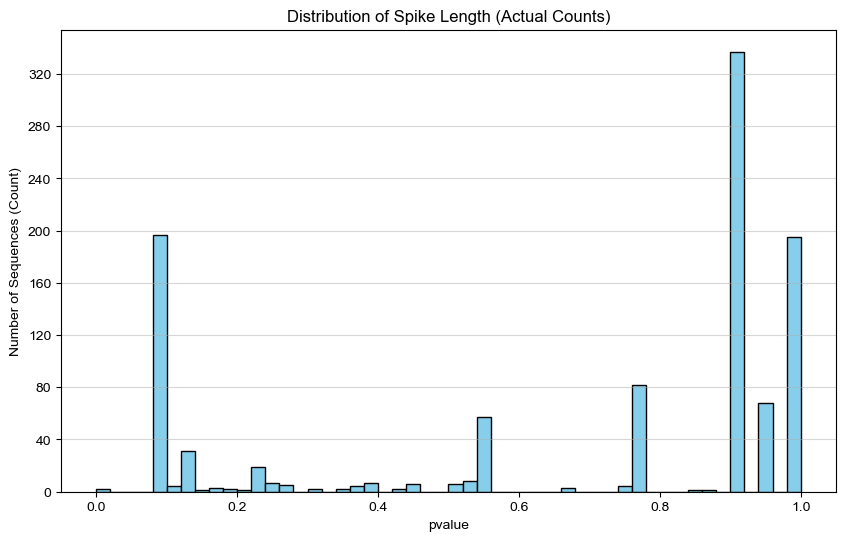

In [46]:
import matplotlib.pyplot as plt
import numpy as np

# 1. データの統計量を表示
print(site_summary['min_p_corrected'].describe())

# 2. ヒストグラムを描画
plt.figure(figsize=(10, 6))
counts, bins, patches = plt.hist(site_summary['min_p_corrected'], bins=50, color='skyblue', edgecolor='black')

# 3. Y軸を整数（件数）として強制的に表示させる設定
plt.gca().yaxis.set_major_locator(plt.MaxNLocator(integer=True))

plt.title('Distribution of Spike Length (Actual Counts)')
plt.xlabel('pvalue')
plt.ylabel('Number of Sequences (Count)') # ラベルを「件数」に変更
plt.grid(axis='y', alpha=0.5)


plt.show()

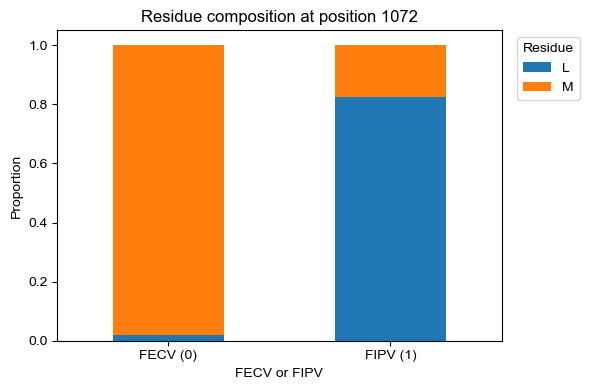

In [47]:
pos = 1072  # 1-based position

df = df_selected.copy()

df["Residue"] = df["Seq"].str[pos-1]

prop = (df.groupby(["FIP_label","Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

prop.plot(kind="bar", stacked=True, figsize=(6,4))
plt.ylabel("Proportion")
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0,1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

In [48]:
# rerun the analysis by 

### FECVをconsensusにした上でアミノ酸の性質変化も考慮して再検討

In [49]:
# FECV consensusの作成
from collections import Counter

# 1. FECVのみ抽出
fecv_df = df_merged_filtered[df_merged_filtered['biotype'] == 'FECV'].copy()

# 2. seqをリスト形式に展開して各ポジションを列にする
# 注意: seqが文字列の場合、リストに変換してDataFrame化します
seq_matrix = pd.DataFrame([list(s) for s in fecv_df['Seq']])

# 3. コンセンサス配列の決定 (各列で最も頻度が高い文字)
consensus = seq_matrix.mode().iloc[0]

# 4. 多型サイトの特定 (ユニークなアミノ酸が2種類以上ある列)
polymorphic_sites = []
for col in seq_matrix.columns:
    counts = seq_matrix[col].value_counts()
    if len(counts) > 1:
        # ポジション（0-indexed）、アミノ酸の種類とカウントを記録
        polymorphic_sites.append({
            'position': col + 1, # 1-based indexにする場合
            'variation': dict(counts)
        })

poly_table = pd.DataFrame(polymorphic_sites)

In [50]:
# コンセンサス配列をリストに変換
consensus_list = consensus.tolist()
# 「一つの長い文字列」にしたい場合
consensus_str = "".join(consensus_list)
print(consensus_str)

MIVLLLALLSTVRSEDAPHG-VTLPQFNTSHNNDKFELNFYNFLQTWDIPPNTETILGGYLPYCGEGDNCGWYNFVYSQNV-G-S-NGKYSYINTQNLNIPNVHGVYFDVRE-H-N-S-D-GVWDARDRVGLLIAIHG-TSHYSLLMVLQDNVEENQPHVAVKICHWK--PGNISSY----HQFSVNLGDGGQCVFNQRFSLDTVLTTNDFYGFQWTDTYVDIYLGGTITKVWVDNDWSVVEASISYHWNRINYGYYIQFVNRTTYYAYNNTGGSNYTHLQLSECH---SDYCAGYAKNVFVPIDGKIPESFSFSNWFLLSDKSTLVQGRVLSSQPVFVQCLRPVPSWSNNTAVVHFKNDVFCPNVTADVLRFNLNFSDTDVYTDSTNDDQLYFTFEDNTTASIACYSSANVTDFQPANNSVSHIPFGKTEHSYFCFANFSHSVVSRQFLGILPPTVREFAFGRDGSIFVNGYKYFSLPPIKSVNFSISSVENYGFWTIAYTNYTDVMVDVNGTGITRLFYCDSPLNRIKCQQLKHELPDGFYSASMLVKKDLPKTFVTMPQFYNWMNVTLHVVLNDTEKGADIILAKAPELASLADIHFEIAQANGSVTNVTSLCVQARQLALFYKYTSLQGLYTYSNLVELQNYDCPFSPQQFNNYLQFETLCFDVNPAVAGCKWSLVHDNKWRTQFATITVSYKDGAMITTMPKAQ-LGFQDISNLVKDECTDYNIYGFQGTGIIRNTTSRLVAGLYYTSISGDLLAFKNSTTGEIFTVVPCDLTAQAAVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSTPV----TVQTYTMPQFYYITKWNNDTSTNCTSVITYSSFAICNTGEIKYVNVTHVEIVDDSIGVIKPISTGNISIPKNFTVAVQAEYIQIQVKPVVVDCAKYVCNGNRHCLSLLTQYTSACQTIENALNLGARLESLMLNDMITVSDRSLELATVEKFNTTALGGEKLGGFYFDGLSSLLPPTI

In [51]:
# 多型テーブルの表示
print("--- 多型サイト一覧 ---")
print(poly_table.head(10))

len(poly_table['position'])

--- 多型サイト一覧 ---
   position                                    variation
0         1                           {'M': 35, '-': 15}
1         2                           {'I': 33, 'M': 17}
2         3  {'V': 18, 'I': 15, 'L': 14, 'F': 2, 'W': 1}
3         4                    {'L': 43, 'V': 5, 'I': 2}
4         5                   {'L': 34, 'I': 15, 'V': 1}
5         6                   {'L': 38, 'F': 10, 'I': 2}
6         7                    {'A': 37, 'V': 8, 'T': 5}
7         8            {'L': 38, 'F': 8, 'I': 3, 'M': 1}
8         9                    {'L': 43, 'F': 5, 'I': 2}
9        10   {'S': 28, 'T': 10, 'G': 6, 'A': 4, 'V': 2}


724

In [52]:
# 多型の閾値設定 (例: 2種類以上、3種類以上など)
threshold = 4  # ここを 3 に変えれば「3種類以上の多型」を抽出します

polymorphic_sites = []
for col in seq_matrix.columns:
    counts = seq_matrix[col].value_counts()
    
    # 閾値でフィルタリング
    if len(counts) >= threshold:
        polymorphic_sites.append({
            'position': col + 1,
            'variation': dict(counts),
            'unique_types': len(counts) # 何種類あるか記録しておくと便利です
        })

poly_table = pd.DataFrame(polymorphic_sites)
print("--- 多型サイト一覧 ---")
print(poly_table.head(10))
len(poly_table['position'])

--- 多型サイト一覧 ---
   position  \
0         3   
1         8   
2        10   
3        11   
4        12   
5        13   
6        14   
7        15   
8        23   
9        26   

                                                            variation  \
0                         {'V': 18, 'I': 15, 'L': 14, 'F': 2, 'W': 1}   
1                                   {'L': 38, 'F': 8, 'I': 3, 'M': 1}   
2                          {'S': 28, 'T': 10, 'G': 6, 'A': 4, 'V': 2}   
3                                  {'T': 24, 'V': 14, 'A': 7, 'I': 5}   
4                                  {'V': 29, 'A': 19, 'T': 1, 'I': 1}   
5  {'R': 25, 'K': 13, 'S': 4, 'G': 3, 'N': 2, 'M': 1, 'H': 1, 'E': 1}   
6                                  {'S': 35, 'A': 13, 'T': 1, 'C': 1}   
7                  {'E': 32, 'H': 12, 'Q': 3, 'N': 1, 'D': 1, 'R': 1}   
8                           {'T': 39, 'I': 6, 'D': 2, 'V': 2, 'X': 1}   
9                          {'Q': 34, 'H': 13, 'Y': 1, 'R': 1, 'L': 1}   

   unique_type

174

In [53]:
# input
seqs = df_selected["Seq"].tolist()
y = df_selected["FIP_label"].to_numpy(dtype=int)

# 多数決で決定したコンセンサス(多型は考慮せず)
fecv_consensus = "MIVLLLALLSTVRSEDAPHG-VTLPQFNTSHNNDKFELNFYNFLQTWDIPPNTETILGGYLPYCGEGDNCGWYNFVYSQNV-G-S-NGKYSYINTQNLNIPNVHGVYFDVRE-H-N-S-D-GVWDARDRVGLLIAIHG-TSHYSLLMVLQDNVEENQPHVAVKICHWK--PGNISSY----HQFSVNLGDGGQCVFNQRFSLDTVLTTNDFYGFQWTDTYVDIYLGGTITKVWVDNDWSVVEASISYHWNRINYGYYIQFVNRTTYYAYNNTGGSNYTHLQLSECH---SDYCAGYAKNVFVPIDGKIPESFSFSNWFLLSDKSTLVQGRVLSSQPVFVQCLRPVPSWSNNTAVVHFKNDVFCPNVTADVLRFNLNFSDTDVYTDSTNDDQLYFTFEDNTTASIACYSSANVTDFQPANNSVSHIPFGKTEHSYFCFANFSHSVVSRQFLGILPPTVREFAFGRDGSIFVNGYKYFSLPPIKSVNFSISSVENYGFWTIAYTNYTDVMVDVNGTGITRLFYCDSPLNRIKCQQLKHELPDGFYSASMLVKKDLPKTFVTMPQFYNWMNVTLHVVLNDTEKGADIILAKAPELASLADIHFEIAQANGSVTNVTSLCVQARQLALFYKYTSLQGLYTYSNLVELQNYDCPFSPQQFNNYLQFETLCFDVNPAVAGCKWSLVHDNKWRTQFATITVSYKDGAMITTMPKAQ-LGFQDISNLVKDECTDYNIYGFQGTGIIRNTTSRLVAGLYYTSISGDLLAFKNSTTGEIFTVVPCDLTAQAAVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSTPV----TVQTYTMPQFYYITKWNNDTSTNCTSVITYSSFAICNTGEIKYVNVTHVEIVDDSIGVIKPISTGNISIPKNFTVAVQAEYIQIQVKPVVVDCAKYVCNGNRHCLSLLTQYTSACQTIENALNLGARLESLMLNDMITVSDRSLELATVEKFNTTALGGEKLGGFYFDGLSSLLPPTIGKRSAVEDLLFNKVVTSGLGTVDDDYKKCSAGTDVADLVCAQYYNGIMVLPGVVDDNKMAMYTASLIGGMAMGSITSAVAVPFAMQVQARLNYVALQTDVLQENQKILANAFNNAIGNITLALGKVSNAITTISDGFNTMASALTKIQSVVNQQGEALSQLTSQLQKNFQAISSSIAEIYNRLEKVEADAQVDRLITGRLAALNAYVSQTLTQYAEVKASRQLAMEKVNECVKSQSDRYGFCGNGTHLFSLVNSAPDGLLFFHTVLLPTEWEEVTAWSGICVNDTYAYVLKDFEYSIFSYNGTYMVTPRNMFQPRKPQMSDFVQITSCEVTFLNTTYTTFQEIVIDYIDINKTIADMLEQYNPNYTTPELDLQLEIFNQTKLNLTAEIDQLEQRADNLTNIAHELQQYIDNLNKTLVDLEWLNRIETYVKWPWYVWLLIGLVVVFCIPLLLFCCLSTGCCGCFGCLGSCCHSLCSRRQFESYEPIEKVHIHX"
L = len(seqs[0])

AA_CLASS = {
    # hydrophobic / aliphatic
    "A": "hydrophobic",
    "V": "hydrophobic",
    "L": "hydrophobic",
    "I": "hydrophobic",
    "M": "hydrophobic",

    # aromatic
    "F": "aromatic",
    "Y": "aromatic",
    "W": "aromatic",

    # polar uncharged
    "S": "polar",
    "T": "polar",
    "N": "polar",
    "Q": "polar",

    # positively charged
    "K": "positive",
    "R": "positive",
    "H": "positive",

    # negatively charged
    "D": "negative",
    "E": "negative",

    # special cases
    "G": "special",
    "P": "special",
    "C": "special",

    # deletion
    #"-": "deletion",
}

INVALID_AA = set(["-", "X", "*", "?", "N"])  


def aa_class(aa):
    if aa in INVALID_AA:
        return None
    return AA_CLASS.get(aa, "other")


def fisher_from_mask(mask, y):
    a = int(np.sum(mask & (y == 1)))
    b = int(np.sum(mask & (y == 0)))
    c = int(np.sum((~mask) & (y == 1)))
    d = int(np.sum((~mask) & (y == 0)))

    OR = (a * d + 1e-9) / (b * c + 1e-9)
    _, p = fisher_exact([[a, b], [c, d]], alternative="two-sided")
    return a, b, c, d, OR, p


records = []

for pos in range(L):
    col = np.array([s[pos] for s in seqs])
    ref = fecv_consensus[pos]

    valid_mask = np.array([(aa not in INVALID_AA) and (ref not in INVALID_AA) for aa in col])

    if ref in INVALID_AA:
        continue

    col_valid = col[valid_mask]
    y_valid = y[valid_mask]

    if len(col_valid) < 3:
        continue

    uniq = np.unique(col_valid)

    # --------------------------------------------------
    # 1) exact mutation test
    # --------------------------------------------------
    for aa in uniq:
        if aa == ref:
            continue

        aa_mask = (col_valid == aa)
        a, b, c, d, OR, p = fisher_from_mask(aa_mask, y_valid)

        records.append({
            "test_type": "exact_aa",
            "feature": f"{ref}{pos+1}{aa}",
            "mutation": f"{ref}{pos+1}{aa}",
            "pos": pos + 1,
            "ref": ref,
            "aa": aa,
            "ref_class": aa_class(ref),
            "aa_class": aa_class(aa),
            "a_case": a,
            "b_ctrl": b,
            "c_case_not": c,
            "d_ctrl_not": d,
            "OR": OR,
            "p": p,
            "n_valid": len(col_valid),
        })

    # --------------------------------------------------
    # 2) any mutation vs no mutation
    # --------------------------------------------------
    any_mut_mask = (col_valid != ref)
    # 変異あり/なしの両方が存在しないと検定できないので確認
    if np.any(any_mut_mask) and np.any(~any_mut_mask):
        a, b, c, d, OR, p = fisher_from_mask(any_mut_mask, y_valid)

        records.append({
            "test_type": "any_mutation",
            "feature": f"{ref}{pos+1}mut",
            "mutation": f"{ref}{pos+1}mut",
            "pos": pos + 1,
            "ref": ref,
            "aa": None,
            "ref_class": aa_class(ref),
            "aa_class": None,
            "a_case": a,
            "b_ctrl": b,
            "c_case_not": c,
            "d_ctrl_not": d,
            "OR": OR,
            "p": p,
            "n_valid": len(col_valid),
        })

    # --------------------------------------------------
    # 3) class changed vs not changed
    # --------------------------------------------------
    ref_cls = aa_class(ref)
    col_cls = np.array([aa_class(aa) for aa in col_valid], dtype=object)

    cls_valid_mask = np.array([c is not None for c in col_cls])
    col_valid2 = col_valid[cls_valid_mask]
    col_cls2 = col_cls[cls_valid_mask]
    y_valid2 = y_valid[cls_valid_mask]

    if len(col_valid2) >= 3 and ref_cls is not None:
        class_changed_mask = (col_cls2 != ref_cls)

        if np.any(class_changed_mask) and np.any(~class_changed_mask):
            a, b, c, d, OR, p = fisher_from_mask(class_changed_mask, y_valid2)

            records.append({
                "test_type": "class_changed",
                "feature": f"{ref}{pos+1}class_change",
                "mutation": f"{ref}{pos+1}class_change",
                "pos": pos + 1,
                "ref": ref,
                "aa": None,
                "ref_class": ref_cls,
                "aa_class": "different_from_ref_class",
                "a_case": a,
                "b_ctrl": b,
                "c_case_not": c,
                "d_ctrl_not": d,
                "OR": OR,
                "p": p,
                "n_valid": len(col_valid2),
            })

    # --------------------------------------------------
    # 4) target class specific tests
    # --------------------------------------------------
    observed_classes = sorted(set([c for c in col_cls if c is not None]))
    for target_cls in observed_classes:
        if target_cls == ref_cls:
            continue

        target_class_mask = (col_cls2 == target_cls)

        if np.any(target_class_mask) and np.any(~target_class_mask):
            a, b, c, d, OR, p = fisher_from_mask(target_class_mask, y_valid2)

            records.append({
                "test_type": "target_class",
                "feature": f"{ref}{pos+1}{target_cls}",
                "mutation": f"{ref}{pos+1}{target_cls}",
                "pos": pos + 1,
                "ref": ref,
                "aa": None,
                "ref_class": ref_cls,
                "aa_class": target_cls,
                "a_case": a,
                "b_ctrl": b,
                "c_case_not": c,
                "d_ctrl_not": d,
                "OR": OR,
                "p": p,
                "n_valid": len(col_valid2),
            })

# =========================
# result table
# =========================
res = pd.DataFrame(records)

res["p_corrected_global"] = multipletests(res["p"], method="fdr_bh")[1]

res["p_corrected_by_type"] = np.nan
for t, idx in res.groupby("test_type").groups.items():
    res.loc[idx, "p_corrected_by_type"] = multipletests(res.loc[idx, "p"], method="fdr_bh")[1]

# =========================
# site summary
# =========================
site_summary = (
    res.groupby(["pos", "test_type"])
       .agg(
           min_p_corrected_global=("p_corrected_global", "min"),
           min_p_corrected_by_type=("p_corrected_by_type", "min"),
           max_abs_logOR=("OR", lambda v: float(np.max(np.abs(np.log(v + 1e-9))))),
           n_features=("feature", "count"),
       )
       .reset_index()
       .sort_values(["min_p_corrected_global", "max_abs_logOR"], ascending=[True, False])
       .reset_index(drop=True)
)

site_summary_overall = (
    res.groupby("pos")
       .agg(
           min_p_corrected_global=("p_corrected_global", "min"),
           min_p_corrected_by_type=("p_corrected_by_type", "min"),
           max_abs_logOR=("OR", lambda v: float(np.max(np.abs(np.log(v + 1e-9))))),
           n_features=("feature", "count"),
       )
       .reset_index()
       .sort_values(["min_p_corrected_global", "max_abs_logOR"], ascending=[True, False])
       .reset_index(drop=True)
)

In [54]:
site_summary

,pos,test_type,min_p_corrected_global,min_p_corrected_by_type,max_abs_logOR,n_features
0,1072,any_mutation,0.000000,0.000000,5.437745,1
1,1072,exact_aa,0.000000,0.000000,5.437745,1
2,814,any_mutation,0.000015,0.000004,28.036486,1
3,1056,any_mutation,0.000018,0.000006,2.330756,1
4,1056,class_changed,0.000018,0.000013,2.330756,1
...,...,...,...,...,...,...
2739,391,target_class,1.000000,1.000000,0.007067,1
2740,511,any_mutation,1.000000,1.000000,0.007067,1
2741,511,exact_aa,1.000000,1.000000,0.007067,1
2742,640,any_mutation,1.000000,1.000000,0.007067,1


In [55]:
site_summary_overall

,pos,min_p_corrected_global,min_p_corrected_by_type,max_abs_logOR,n_features
0,1072,0.000000,0.000000,5.437745,2
1,814,0.000015,0.000004,28.036486,13
2,1056,0.000018,0.000006,26.244727,13
3,1133,0.004101,0.001451,27.631021,6
4,1363,0.014754,0.006036,26.427048,11
...,...,...,...,...,...
779,1425,1.000000,1.000000,0.080827,2
780,526,1.000000,1.000000,0.029853,2
781,959,1.000000,1.000000,0.013986,2
782,391,1.000000,1.000000,0.007067,4


In [56]:
# 1. P値が 0.05 未満のポジションを特定
significant_pos = site_summary[site_summary["min_p_corrected_by_type"] < 0.05]["pos"]

# 2. そのポジションの詳細（検定タイプ含む）を site_summary から抽出
detailed_table = site_summary[site_summary["pos"].isin(significant_pos)].copy()

# 3. 見やすくするために並び替え（P値の小さい順）
detailed_table = detailed_table.sort_values("min_p_corrected_by_type")

# 表示
print(detailed_table[["pos", "test_type", "min_p_corrected_by_type", "max_abs_logOR", "n_features"]])
len(detailed_table["pos"])

      pos      test_type  min_p_corrected_by_type  max_abs_logOR  n_features
0    1072   any_mutation                 0.000000       5.437745           1
1    1072       exact_aa                 0.000000       5.437745           1
2     814   any_mutation                 0.000004      28.036486           1
3    1056   any_mutation                 0.000006       2.330756           1
4    1056  class_changed                 0.000013       2.330756           1
5     814  class_changed                 0.000228      27.813343           1
9    1133   any_mutation                 0.001451       3.239495           1
6    1133  class_changed                 0.001864      27.631021           1
11   1363  class_changed                 0.006036       2.505960           1
10   1363   any_mutation                 0.006438       2.505960           1
7    1133       exact_aa                 0.009174      27.631021           3
12    811   any_mutation                 0.009587       2.966051           1

26

In [57]:
detailed_table

,pos,test_type,min_p_corrected_global,min_p_corrected_by_type,max_abs_logOR,n_features
0,1072,any_mutation,0.000000,0.000000,5.437745,1
1,1072,exact_aa,0.000000,0.000000,5.437745,1
2,814,any_mutation,0.000015,0.000004,28.036486,1
3,1056,any_mutation,0.000018,0.000006,2.330756,1
4,1056,class_changed,0.000018,0.000013,2.330756,1
5,814,class_changed,0.000558,0.000228,27.813343,1
9,1133,any_mutation,0.004101,0.001451,3.239495,1
6,1133,class_changed,0.004101,0.001864,27.631021,1
11,1363,class_changed,0.014754,0.006036,2.505960,1
10,1363,any_mutation,0.014754,0.006438,2.505960,1


In [58]:
# ピボットテーブル化: 行=pos, 列=test_type, 値=P値
pivot_table = detailed_table.pivot(index="pos", columns="test_type", values="min_p_corrected_by_type")

# 結果を表示
print(pivot_table.head(10))

test_type  any_mutation  class_changed  exact_aa  target_class
pos                                                           
811            0.009587       0.058710  0.905857      0.882408
814            0.000004       0.000228  0.502426      0.287510
1056           0.000006       0.000013  0.540005      0.782386
1072           0.000000            NaN  0.000000           NaN
1133           0.001451       0.001864  0.009174      0.009616
1363           0.006438       0.006036  0.789249      0.882408
1368           0.032014       0.033614  0.349754      0.249918


In [59]:
# mutationの性質(test_type)のカラムでp<0.05 をハイライト
# 背景色を塗る関数を定義
def highlight_low_p(val):
    color = 'yellow' if val < 0.05 else ''
    return f'background-color: {color}'

# スタイルを適用して表示
# .format("{:.10f}") で小数点表記、.applymap でハイライトを適用
styled_table = pivot_table.head(10).style \
    .format("{:.10f}") \
    .applymap(highlight_low_p)

styled_table

/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_12520/1010008509.py:11: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  .applymap(highlight_low_p)


test_type,any_mutation,class_changed,exact_aa,target_class
pos,,,,
811,0.0095865745,0.0587103363,0.9058565231,0.8824084495
814,0.0000041412,0.0002280764,0.5024258298,0.2875103680
1056,0.0000055726,0.0000125383,0.5400054390,0.7823855230
1072,0.0000000000,nan,0.0000000000,nan
1133,0.0014513924,0.0018642365,0.0091737558,0.0096160365
1363,0.0064383195,0.0060359246,0.7892492163,0.8824084495
1368,0.0320137712,0.0336144598,0.3497543816,0.2499177561


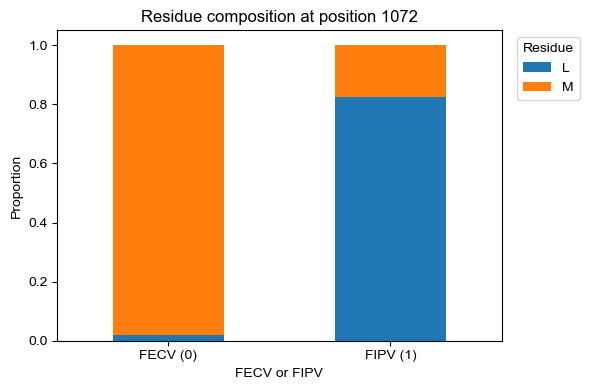

In [47]:
pos = 1072  # 1-based position

df = df_selected.copy()

df["Residue"] = df["Seq"].str[pos-1]

prop = (df.groupby(["FIP_label","Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

prop.plot(kind="bar", stacked=True, figsize=(6,4))
plt.ylabel("Proportion")
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0,1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

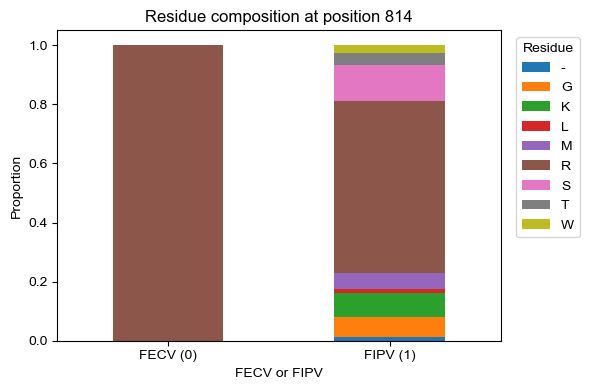

In [43]:
pos = 814  # 1-based position

df = df_selected.copy()

df["Residue"] = df["Seq"].str[pos-1]

prop = (df.groupby(["FIP_label","Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

prop.plot(kind="bar", stacked=True, figsize=(6,4))
plt.ylabel("Proportion")
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0,1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

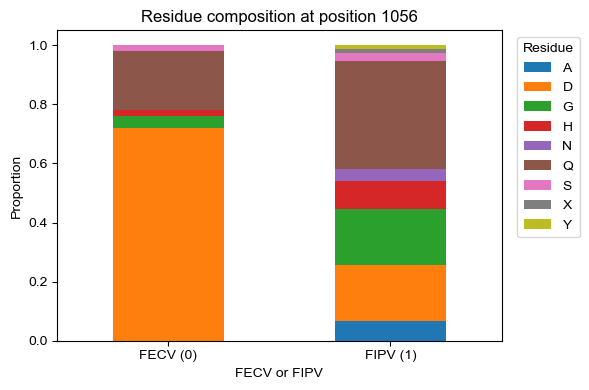

In [46]:
pos = 1056  # 1-based position

df = df_selected.copy()

df["Residue"] = df["Seq"].str[pos-1]

prop = (df.groupby(["FIP_label","Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

prop.plot(kind="bar", stacked=True, figsize=(6,4))
plt.ylabel("Proportion")
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0,1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

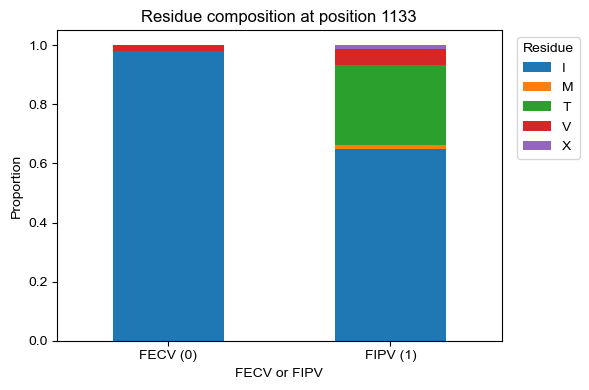

In [48]:
pos = 1133  # 1-based position

df = df_selected.copy()

df["Residue"] = df["Seq"].str[pos-1]

prop = (df.groupby(["FIP_label","Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

prop.plot(kind="bar", stacked=True, figsize=(6,4))
plt.ylabel("Proportion")
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0,1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

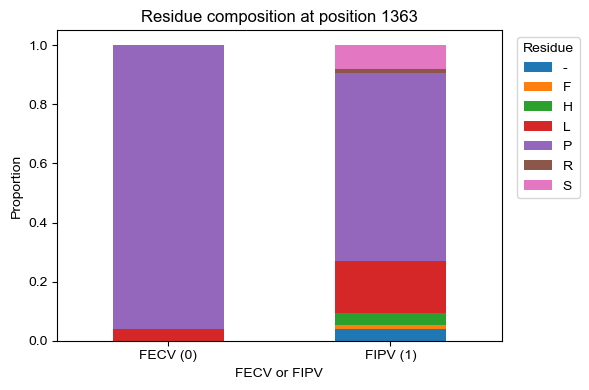

In [ ]:
pos = 1363  # 1-based position

df = df_selected.copy()

df["Residue"] = df["Seq"].str[pos-1]

prop = (df.groupby(["FIP_label","Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

prop.plot(kind="bar", stacked=True, figsize=(6,4))
plt.ylabel("Proportion")
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0,1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

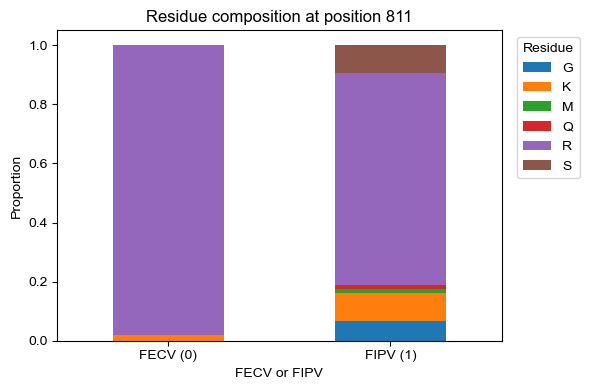

In [50]:
pos = 811  # 1-based position

df = df_selected.copy()

df["Residue"] = df["Seq"].str[pos-1]

prop = (df.groupby(["FIP_label","Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

prop.plot(kind="bar", stacked=True, figsize=(6,4))
plt.ylabel("Proportion")
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0,1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

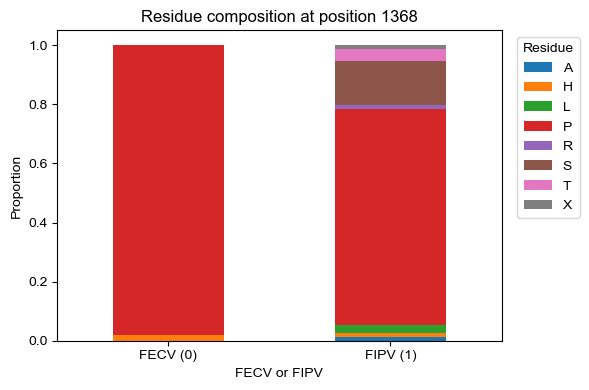

In [51]:
pos = 1368  # 1-based position

df = df_selected.copy()

df["Residue"] = df["Seq"].str[pos-1]

prop = (df.groupby(["FIP_label","Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

prop.plot(kind="bar", stacked=True, figsize=(6,4))
plt.ylabel("Proportion")
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0,1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

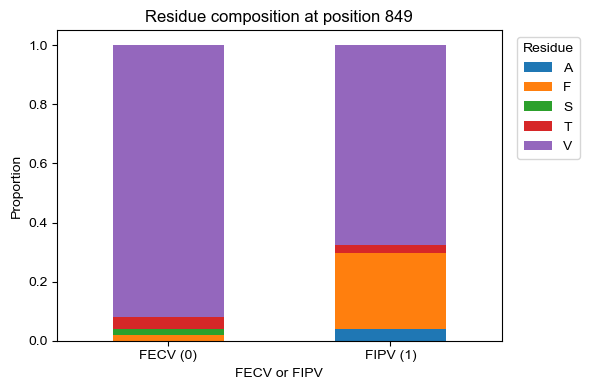

In [52]:
pos = 849  # 1-based position

df = df_selected.copy()

df["Residue"] = df["Seq"].str[pos-1]

prop = (df.groupby(["FIP_label","Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

prop.plot(kind="bar", stacked=True, figsize=(6,4))
plt.ylabel("Proportion")
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0,1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

### fecv consensusの多型を考慮してconsensusに選ばれなかった30%以上のfrequencyのアミノ酸をconsensusとして検定

In [ ]:
# 出現頻度が30%以上の多型でも同様に検定
# サンプル数を取得する ---
n_samples = len(fecv_df)

major_poly_highlighted = []

for site in polymorphic_sites:
    pos = site['position']
    variations = site['variation']
    
    # 頻度計算
    freq_dist = {amino: count / n_samples for amino, count in variations.items()}
    # 30%以上のものだけを抽出
    high_freq_vars = {amino: f"{freq:.1%}" for amino, freq in freq_dist.items() if freq >= 0.3}
    
    # 30%以上が2つ以上ある場合のみ処理
    if len(high_freq_vars) >= 2:
        # このポジションのコンセンサス文字を取得
        con_char = consensus[pos - 1]
        
        # コンセンサス文字に星印（★）をつける、または辞書内で目立たせる
        highlighted_vars = {}
        for amino, perc in high_freq_vars.items():
            if amino == con_char:
                highlighted_vars[f"★{amino}(consensus)"] = perc
            else:
                highlighted_vars[amino] = perc
                
        major_poly_highlighted.append({
            'position': pos,
            'variants_with_consensus': highlighted_vars,
            'total_variants': len(variations)
        })

# 結果を表示
df_highlighted = pd.DataFrame(major_poly_highlighted)
pd.set_option('display.max_colwidth', None)
print(df_highlighted)

    position                   variants_with_consensus  total_variants
0          1  {'★M(consensus)': '70.0%', '-': '30.0%'}               2
1          2  {'★I(consensus)': '66.0%', 'M': '34.0%'}               2
2          3  {'★V(consensus)': '36.0%', 'I': '30.0%'}               5
3          5  {'★L(consensus)': '68.0%', 'I': '30.0%'}               3
4         12  {'★V(consensus)': '58.0%', 'A': '38.0%'}               4
5         31  {'★H(consensus)': '44.0%', 'Y': '44.0%'}               4
6         88  {'★G(consensus)': '66.0%', 'A': '30.0%'}               3
7        116  {'★N(consensus)': '50.0%', 'D': '34.0%'}               7
8        129  {'★R(consensus)': '64.0%', 'K': '32.0%'}               3
9        140  {'★T(consensus)': '34.0%', 'K': '32.0%'}               7
10       187  {'★N(consensus)': '52.0%', 'D': '32.0%'}               5
11       205  {'★V(consensus)': '36.0%', 'K': '32.0%'}               4
12       208  {'★T(consensus)': '54.0%', 'A': '44.0%'}               3
13    

In [31]:
n_samples

50

In [34]:
import pandas as pd
import numpy as np
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

re_test_records = []


# --- 1. 再検定ループの実行 ---
for item in major_poly_highlighted:
    pos_1based = item['position']
    pos_0indexed = pos_1based - 1
    
    # コンセンサス以外の30%以上の多型アミノ酸を基準にする
    high_freq_vars = item['variants_with_consensus']
    new_refs = [aa.replace('★', '').replace('(consensus)', '') 
                for aa in high_freq_vars.keys() if '★' not in aa]
    
    col = np.array([s[pos_0indexed] for s in seqs])
    
    for ref in new_refs:
        # 有効データのフィルタリング
        valid_mask = np.array([(aa not in INVALID_AA) and (ref not in INVALID_AA) for aa in col])
        col_valid = col[valid_mask]
        y_valid = y[valid_mask]
        if len(col_valid) < 3: continue

        # --- A) Exact AA & Any Mutation ---
        uniq = np.unique(col_valid)
        for aa in uniq:
            if aa == ref: continue
            aa_mask = (col_valid == aa)
            a, b, c, d, OR, p = fisher_from_mask(aa_mask, y_valid)
            re_test_records.append({
                "test_type": "exact_aa", "pos": pos_1based, "new_ref": ref,
                "feature": f"{ref}{pos_1based}{aa}", "p": p, "OR": OR, "a_case": a, "b_ctrl": b
            })

        any_mut_mask = (col_valid != ref)
        if np.any(any_mut_mask) and np.any(~any_mut_mask):
            a, b, c, d, OR, p = fisher_from_mask(any_mut_mask, y_valid)
            re_test_records.append({
                "test_type": "any_mutation", "pos": pos_1based, "new_ref": ref,
                "feature": f"{ref}{pos_1based}mut", "p": p, "OR": OR, "a_case": a, "b_ctrl": b
            })

        # --- B) Class Based Test ---
        ref_cls = aa_class(ref)
        col_cls = np.array([aa_class(aa) for aa in col_valid], dtype=object)
        cls_valid_mask = np.array([c is not None for c in col_cls])
        col_cls2 = col_cls[cls_valid_mask]; y_valid2 = y_valid[cls_valid_mask]

        if len(col_cls2) >= 3 and ref_cls is not None:
            # 性質変化
            class_changed_mask = (col_cls2 != ref_cls)
            if np.any(class_changed_mask) and np.any(~class_changed_mask):
                a, b, c, d, OR, p = fisher_from_mask(class_changed_mask, y_valid2)
                re_test_records.append({
                    "test_type": "class_changed", "pos": pos_1based, "new_ref": ref,
                    "feature": f"{ref}{pos_1based}class_change", "p": p, "OR": OR, "a_case": a, "b_ctrl": b
                })

            # 特定の性質への変化
            observed_classes = sorted(set([c for c in col_cls2 if c is not None]))
            for target_cls in observed_classes:
                if target_cls == ref_cls: continue
                target_class_mask = (col_cls2 == target_cls)
                if np.any(target_class_mask) and np.any(~target_class_mask):
                    a, b, c, d, OR, p = fisher_from_mask(target_class_mask, y_valid2)
                    re_test_records.append({
                        "test_type": "target_class", "pos": pos_1based, "new_ref": ref,
                        "feature": f"{ref}{pos_1based}{target_cls}", "p": p, "OR": OR, "a_case": a, "b_ctrl": b
                    })

# --- 2. P値の補正と集計 ---
if re_test_records:
    res_retest = pd.DataFrame(re_test_records)
    # 全体でのFDR補正
    res_retest["p_corrected_global"] = multipletests(res_retest["p"], method="fdr_bh")[1]

    # --- 3. ピボットテーブル化 ---
    # 各pos, new_refに対して、各検定タイプの最小P値を表示
    retest_pivot = res_retest.pivot_table(
        index=["pos", "new_ref"], 
        columns="test_type", 
        values="p_corrected_global",
        aggfunc='min'
    )

    # --- 4. スタイリング（小数点表示とハイライト） ---
    styled_retest = retest_pivot.style.format("{:.10f}", na_rep="-").applymap(
        lambda val: 'background-color: #ffffb3; font-weight: bold;' if (not pd.isna(val) and val < 0.1) else ''
    )
    
    # 表示
    display(styled_retest)

/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_12520/3337203677.py:91: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled_retest = retest_pivot.style.format("{:.10f}", na_rep="-").applymap(


,test_type,any_mutation,class_changed,exact_aa,target_class
pos,new_ref,,,,
2,M,0.4171661458,-,0.4171661458,-
3,I,0.2494336350,1.0000000000,0.5250249201,0.9583286493
5,I,0.5439804973,1.0000000000,0.4171661458,1.0000000000
12,A,0.9583286493,0.9583286493,0.9583286493,0.9583286493
31,Y,0.2494336350,0.4171661458,0.5886256145,0.5886256145
88,A,0.5954369031,0.7507529010,0.9562667458,0.9562667458
116,D,0.9583286493,0.9583286493,0.9583286493,0.9583286493
129,K,0.7499943318,0.7499943318,0.7499943318,0.7499943318
140,K,1.0000000000,1.0000000000,0.6997864516,0.7499943318


### deletionの有無による検定

In [13]:
import re
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact

# 1. 解析対象の配列とラベルの準備
# S1領域 (pos 1-814) のみにスライス
s1_seqs = [s[:814] for s in df_selected["Seq"].tolist()]
y = df_selected["FIP_label"].to_numpy(int)

# 2. 「40連以上のギャップがあるか」を判定するフラグを作成
# 正規表現で '-' が4回以上続く箇所を探します
has_long_gap = []
for seq in s1_seqs:
    if re.search(r'-{40,}', seq):
        has_long_gap.append(True)
    else:
        has_long_gap.append(False)

has_long_gap = np.array(has_long_gap)

# 3. 2×2分割表の作成
# [long_gapあり ∩ FIPV, long_gapあり ∩ FECV]
# [long_gapなし ∩ FIPV, long_gapなし ∩ FECV]
a = int(np.sum(has_long_gap & (y == 1)))
b = int(np.sum(has_long_gap & (y == 0)))
c = int(np.sum((~has_long_gap) & (y == 1)))
d = int(np.sum((~has_long_gap) & (y == 0)))

# 4. フィッシャーの正確確率検定
OR = (a * d + 1e-9) / ((b * c) + 1e-9)
p_value, _ = fisher_exact([[a, b], [c, d]], alternative="two-sided")

# 5. 結果の表示
ntd_gap_res = pd.DataFrame([{
    "Range": "domain0 (1-294)",
    "Feature": "40+ consecutive gaps",
    "FIPV_with_gap": a,
    "FECV_with_gap": b,
    "FIPV_without_gap": c,
    "FECV_without_gap": d,
    "Odds_Ratio": OR,
    "p_value": p_value
}])

print("--- domain0周辺領域(1-294)における40連以上の欠損と病型の相関 ---")
display(ntd_gap_res.style.format({"p_value": "{:.10f}", "Odds_Ratio": "{:.4f}"}))

--- domain0周辺領域(1-294)における40連以上の欠損と病型の相関 ---


,Range,Feature,FIPV_with_gap,FECV_with_gap,FIPV_without_gap,FECV_without_gap,Odds_Ratio,p_value
0,domain0 (1-294),40+ consecutive gaps,11,1,63,49,8.5556,8.5555555556


In [ ]:
### domain 0 1-294

In [84]:
# domain 0(1-294)に絞る

import re
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact

# 1. 解析対象の領域を pos 1-294 に限定してスライス
# (Pythonのインデックスは0からなので [:300] が 1-300 に相当)
ntd_seqs = [s[:294] for s in df_selected["Seq"].tolist()]
y = df_selected["FIP_label"].to_numpy(int)

# 2. 「40連以上のギャップがあるか」を判定
has_large_gap_ntd = []
for seq in ntd_seqs:
    # '-' が40個以上連続している箇所を検索
    if re.search(r'-{40,}', seq):
        has_large_gap_ntd.append(True)
    else:
        has_large_gap_ntd.append(False)

has_large_gap_ntd = np.array(has_large_gap_ntd)

# 3. 2×2分割表の作成
a = int(np.sum(has_large_gap_ntd & (y == 1)))  # FIPV with gap
b = int(np.sum(has_large_gap_ntd & (y == 0)))  # FECV with gap
c = int(np.sum((~has_large_gap_ntd) & (y == 1))) # FIPV without gap
d = int(np.sum((~has_large_gap_ntd) & (y == 0))) # FECV without gap

# 4. フィッシャーの正確確率検定
OR = (a * d + 1e-9) / ((b * c) + 1e-9)
p_value, _ = fisher_exact([[a, b], [c, d]], alternative="two-sided")

# 5. 結果の表示
ntd_gap_res = pd.DataFrame([{
    "Range": "domain0 (1-294)",
    "Feature": "40+ consecutive gaps",
    "FIPV_with_gap": a,
    "FECV_with_gap": b,
    "FIPV_without_gap": c,
    "FECV_without_gap": d,
    "Odds_Ratio": OR,
    "p_value": p_value
}])

print("--- domain0周辺領域(1-294)における40連以上の欠損と病型の相関 ---")
display(ntd_gap_res.style.format({"p_value": "{:.10f}", "Odds_Ratio": "{:.4f}"}))

--- domain0周辺領域(1-294)における40連以上の欠損と病型の相関 ---


,Range,Feature,FIPV_with_gap,FECV_with_gap,FIPV_without_gap,FECV_without_gap,Odds_Ratio,p_value
0,domain0 (1-294),40+ consecutive gaps,10,0,64,50,500000000000.9999,inf


＃ p valueが inf となる問題を解消

In [10]:
# 1. 解析対象の領域を pos 1-294 に限定してスライス
ntd_seqs = [s[:294] for s in df_selected["Seq"].tolist()]
y = df_selected["FIP_label"].to_numpy(int)

# 2. 「40連以上のギャップがあるか」を判定
has_large_gap_ntd = [bool(re.search(r'-{40,}', seq)) for seq in ntd_seqs]
has_large_gap_ntd = np.array(has_large_gap_ntd)

# 3. 2×2分割表の作成
a = int(np.sum(has_large_gap_ntd & (y == 1)))
b = int(np.sum(has_large_gap_ntd & (y == 0)))
c = int(np.sum((~has_large_gap_ntd) & (y == 1)))
d = int(np.sum((~has_large_gap_ntd) & (y == 0)))

# 4. フィッシャーの正確確率検定
# 計算結果を直接受け取る
odds_ratio, p_value = fisher_exact([[a, b], [c, d]], alternative="two-sided")

# 5. 結果の表示
ntd_gap_res = pd.DataFrame([{
    "Range": "domain0 (1-294)",
    "Feature": "40+ consecutive gaps",
    "FIPV_with_gap": a,
    "FECV_with_gap": b,
    "FIPV_without_gap": c,
    "FECV_without_gap": d,
    "Odds_Ratio": odds_ratio,
    "p_value": p_value
}])

# 表示設定をグローバルに適用して inf を防ぐ
pd.options.display.float_format = '{:.6f}'.format
print("--- domain0周辺領域(1-294)における40連以上の欠損と病型の相関 ---")
display(ntd_gap_res)

--- domain0周辺領域(1-294)における40連以上の欠損と病型の相関 ---


,Range,Feature,FIPV_with_gap,FECV_with_gap,FIPV_without_gap,FECV_without_gap,Odds_Ratio,p_value
0,domain0 (1-294),40+ consecutive gaps,10,0,64,50,inf,0.005602


In [11]:
p_value

np.float64(0.0056017531651243865)

4 deletion以上で検定

In [85]:
import re
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact

# 1. 解析対象の領域 (1-294) をスライス
# インデックス 0-293 が 1-294 に相当
target_seqs = [s[:294] for s in df_selected["Seq"].tolist()]
y = df_selected["FIP_label"].to_numpy(int)

# 2.c57のみに見られる4aaのinsertionのため178-182 (0-indexedでは 177-182) を無視して4連以上の欠損を判定
has_filtered_gap = []
for seq in target_seqs:
    # 配列をリスト化して操作
    temp_seq_list = list(seq)
    
    # 178-182番目 (index 177, 178, 179, 180, 181) を 'X' に置換
    # これにより、この部分にあるハイフンは連続カウントされなくなる
    for i in range(177, 182):
        if i < len(temp_seq_list):
            temp_seq_list[i] = 'X'
    
    # 再び文字列に戻す
    filtered_seq = "".join(temp_seq_list)
    
    # 'X' を除いた部分で '-' が4回以上連続しているか判定
    if re.search(r'-{4,}', filtered_seq):
        has_filtered_gap.append(True)
    else:
        has_filtered_gap.append(False)

has_filtered_gap = np.array(has_filtered_gap)

# 3. 2×2分割表の作成
a = int(np.sum(has_filtered_gap & (y == 1)))
b = int(np.sum(has_filtered_gap & (y == 0)))
c = int(np.sum((~has_filtered_gap) & (y == 1)))
d = int(np.sum((~has_filtered_gap) & (y == 0)))

# 4. フィッシャーの正確確率検定
OR = (a * d + 1e-9) / ((b * c) + 1e-9)
p_value, _ = fisher_exact([[a, b], [c, d]], alternative="two-sided")

# 5. 結果の表示
filtered_gap_res = pd.DataFrame([{
    "Range": "1-294 (excl. 178-182)",
    "Feature": "4+ consecutive gaps",
    "FIPV_with_gap": a,
    "FECV_with_gap": b,
    "FIPV_without_gap": c,
    "FECV_without_gap": d,
    "Odds_Ratio": OR,
    "p_value": p_value
}])

print("--- 178-182を除外した領域(1-294)における4連以上欠損の検定 ---")
display(filtered_gap_res.style.format({"p_value": "{:.10f}", "Odds_Ratio": "{:.4f}"}))

--- 178-182を除外した領域(1-294)における4連以上欠損の検定 ---


,Range,Feature,FIPV_with_gap,FECV_with_gap,FIPV_without_gap,FECV_without_gap,Odds_Ratio,p_value
0,1-294 (excl. 178-182),4+ consecutive gaps,14,0,60,50,700000000001.0000,inf


2 deletionで検定, insertion箇所を除く

In [86]:
import re
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact

# 1. 解析対象の領域 (1-294) をスライス
target_seqs = [s[:294] for s in df_selected["Seq"].tolist()]
y = df_selected["FIP_label"].to_numpy(int)

# 2. 指定の3領域を無視して「2連以上」の欠損を判定
has_filtered_gap_2 = []
for seq in target_seqs:
    temp_seq_list = list(seq)
    
    # 無視したいポジションのインデックスリスト
    # 169-170番目 -> index 168, 169
    # 178-182番目 -> index 177, 178, 179, 180, 181
    # 287-289番目 -> index 286, 287, 288
    ignore_indices = [168, 169, 177, 178, 179, 180, 181, 286, 287, 288]
    
    for i in ignore_indices:
        if i < len(temp_seq_list):
            temp_seq_list[i] = 'X'
    
    filtered_seq = "".join(temp_seq_list)
    
    # '-' が2回以上連続しているか判定 (r'-{2,}')
    if re.search(r'-{2,}', filtered_seq):
        has_filtered_gap_2.append(True)
    else:
        has_filtered_gap_2.append(False)

has_filtered_gap_2 = np.array(has_filtered_gap_2)

# 3. 2×2分割表の作成
a = int(np.sum(has_filtered_gap_2 & (y == 1))) # FIPV with gap
b = int(np.sum(has_filtered_gap_2 & (y == 0))) # FECV with gap
c = int(np.sum((~has_filtered_gap_2) & (y == 1))) # FIPV without gap
d = int(np.sum((~has_filtered_gap_2) & (y == 0))) # FECV without gap

# 4. フィッシャーの正確確率検定
OR = (a * d + 1e-9) / ((b * c) + 1e-9)
p_value, _ = fisher_exact([[a, b], [c, d]], alternative="two-sided")

# 5. 結果の表示
filtered_gap_res_2 = pd.DataFrame([{
    "Range": "1-294 (excl. 3 regions)",
    "Feature": "2+ consecutive gaps",
    "FIPV_with_gap": a,
    "FECV_with_gap": b,
    "FIPV_without_gap": c,
    "FECV_without_gap": d,
    "Odds_Ratio": OR,
    "p_value": p_value
}])

print("--- 指定3領域を除外した領域(1-294)における2連以上欠損の検定 ---")
display(filtered_gap_res_2.style.format({"p_value": "{:.10f}", "Odds_Ratio": "{:.4f}"}))

--- 指定3領域を除外した領域(1-294)における2連以上欠損の検定 ---


,Range,Feature,FIPV_with_gap,FECV_with_gap,FIPV_without_gap,FECV_without_gap,Odds_Ratio,p_value
0,1-294 (excl. 3 regions),2+ consecutive gaps,23,5,51,45,4.0588,4.0588235294
